### Notebook 1 - Clase 

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 

In [3]:
type(pd)

module

In [4]:
filename = "../oni_mensual_1981_2026.csv"
type(filename)

str

In [5]:
oni = pd.read_csv(filename, parse_dates=["time"])

In [6]:
oni

,time,oni_degC
0,1981-09-01,-0.25
1,1981-10-01,-0.16
2,1981-11-01,-0.13
3,1981-12-01,-0.15
4,1982-01-01,-0.08
...,...,...
535,2026-04-01,0.11
536,2026-05-01,0.46
537,2026-06-01,0.95
538,2026-07-01,1.39


In [7]:
oni.head(10)

,time,oni_degC
0,1981-09-01,-0.25
1,1981-10-01,-0.16
2,1981-11-01,-0.13
3,1981-12-01,-0.15
4,1982-01-01,-0.08
5,1982-02-01,-0.05
6,1982-03-01,0.07
7,1982-04-01,0.19
8,1982-05-01,0.47
9,1982-06-01,0.66


In [8]:
type(oni)

pandas.DataFrame

In [9]:
oni.columns

Index(['time', 'oni_degC'], dtype='str')

In [10]:
oni.shape

(540, 2)

In [11]:
oni.dtypes

time        datetime64[us]
oni_degC           float64
dtype: object

In [12]:
oni.describe()

,time,oni_degC
count,540,540.000000
mean,2004-02-15 08:00:00,0.046185
min,1981-09-01 00:00:00,-1.850000
25%,1992-11-23 12:00:00,-0.552500
50%,2004-02-15 12:00:00,-0.075000
75%,2015-05-08 18:00:00,0.572500
max,2026-08-01 00:00:00,2.750000
std,NaN,0.871231


### ¿Cuantos meses tiene el archivo? 
### ¿Cuál es el valor máximo y mínimo de oni_degC? 
### ¿Qué fecha corresponde al valor máximo? 

In [13]:
oni.min()

time        1981-09-01 00:00:00
oni_degC                  -1.85
dtype: object

In [14]:
oni.max()

time        2026-08-01 00:00:00
oni_degC                   2.75
dtype: object

#### Solucion: 

*Meses:*

In [15]:
len(oni)

540

In [16]:
oni["oni_degC"].max()

np.float64(2.75)

In [17]:
oni.iloc[0]

time        1981-09-01 00:00:00
oni_degC                  -0.25
Name: 0, dtype: object

In [18]:
oni.oni_degC > 0.5

0      False
1      False
2      False
3      False
4      False
       ...  
535    False
536    False
537     True
538     True
539     True
Name: oni_degC, Length: 540, dtype: bool

In [19]:
type(oni.oni_degC > 0.5)

pandas.Series

In [20]:
nino = oni.loc[oni.oni_degC > 0.5]

In [21]:
len(nino)

145

In [22]:
nino

,time,oni_degC
9,1982-06-01,0.66
10,1982-07-01,0.72
11,1982-08-01,0.79
12,1982-09-01,1.07
13,1982-10-01,1.58
...,...,...
511,2024-04-01,1.26
512,2024-05-01,0.82
537,2026-06-01,0.95
538,2026-07-01,1.39


**Condicionales**

In [23]:
x = 1.2 
if x >= 0.5:
    print("niño")
elif x <= -0.5:
    print("niña")
else:
    print("neutro")

niño


**Hacer funciones**

In [24]:
def enso_phase(oni_value): 
    '''Esta funcion me dice la fase del ENSO dependiendo del valor del ONI '''
    if oni_value >= 0.5:
        return "El Niño"
    elif oni_value <= -0.5: 
        return "La Niña" 
    else:
        return "Neutral"

In [25]:
enso_phase(-0.7)

'La Niña'

In [26]:
enso_phase(0.2)

'Neutral'

In [27]:
?enso_phase

Signature: enso_phase(oni_value)
Docstring: Esta funcion me dice la fase del ENSO dependiendo del valor del ONI 
File:      ~\appdata\local\temp\ipykernel_4152\2313002736.py
Type:      function

**Ciclos**

In [28]:
values = [1.2, -0.7, 0.0]

for value in values:
    print(value, enso_phase(value))

1.2 El Niño
-0.7 La Niña
0.0 Neutral


In [29]:
oni["phase"] = oni.oni_degC.apply(enso_phase)

oni.head(40)

,time,oni_degC,phase
0,1981-09-01,-0.25,Neutral
1,1981-10-01,-0.16,Neutral
2,1981-11-01,-0.13,Neutral
3,1981-12-01,-0.15,Neutral
4,1982-01-01,-0.08,Neutral
5,1982-02-01,-0.05,Neutral
6,1982-03-01,0.07,Neutral
7,1982-04-01,0.19,Neutral
8,1982-05-01,0.47,Neutral
9,1982-06-01,0.66,El Niño


In [30]:
rain = pd.read_csv("../precipitacion_ensenada_1981_2026.csv", parse_dates=["time"])
rain.head()

,time,precip_mm
0,1981-09-01,2.0
1,1981-10-01,5.0
2,1981-11-01,68.5
3,1981-12-01,20.0
4,1982-01-01,54.8


In [31]:
rain.info()

<class 'pandas.DataFrame'>
RangeIndex: 540 entries, 0 to 539
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   time       540 non-null    datetime64[us]
 1   precip_mm  511 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 8.6 KB


In [32]:
rain.isna().sum()

time          0
precip_mm    29
dtype: int64

## Gráficas 

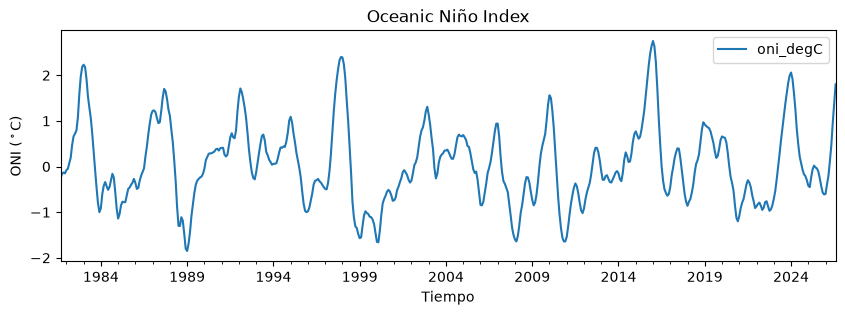

In [33]:
#Gráfica del ONI
oni.plot(x="time", y="oni_degC", figsize = (10,3))
plt.ylabel(r"ONI ($^\circ$C)")
plt.xlabel("Tiempo")
plt.title('Oceanic Niño Index')
plt.show()

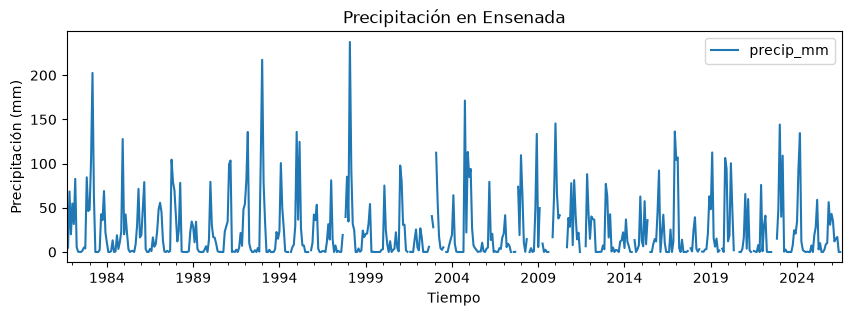

In [34]:
#Gráfica de la precipitación
rain.plot(x="time", y="precip_mm", figsize = (10,3))
plt.ylabel(r"Precipitación (mm)")
plt.xlabel("Tiempo")
plt.title('Precipitación en Ensenada')
plt.show()

### Tarea: Encuentra los meses para los que no tenemos datos de precipitación  

In [36]:
meses_nan = rain.index[rain.isna()]
print(meses_nan)

Index([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       ...
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
      dtype='int64', length=540)
